# Additive vs MULTI-evolve comparison — dCasRx

Compare additive (RidgeCV) predictions against MULTI-evolve 1-layer NN
predictions across the full combinatorial mutation space.

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
import os

In [2]:
effect_dictionary = {}

full_df = pd.read_excel('../data/Table S15 dCasRx variants.xlsx')
full_df = full_df[[x for x in full_df.columns.values if 'Unnamed' not in x]]
# Transform fold improvement into log2 space
full_df[f'logfc'] = full_df['Fold Improvement (gTSM only)'].apply(np.log2)
full_df

,Mutations,Fold Improvement (gTSM only),Origin,Variant ID,Legend,logfc
0,WT,1.000000,NaN,NaN,WT = wild-type sequence,0.000000
1,P91K,1.830000,DMS,NaN,Mutations are formatted as {original amino aci...,0.871844
2,A134H,1.335000,DMS,NaN,NaN,0.416840
3,E173N,1.162000,DMS,NaN,NaN,0.216610
4,N226R,1.055000,DMS,NaN,NaN,0.077243
...,...,...,...,...,...,...
204,P91K/A134H/H240F/E282W/S354P/D417R,3.980903,MULTI-evolve variant,v528,NaN,1.993096
205,P91K/A134H/D261H/E282W/S354P/D417R,6.107955,MULTI-evolve variant,v529,NaN,2.610689
206,P91K/A134H/H240F/E282W/S354P/L385R/D417R,4.399047,MULTI-evolve variant,v530,NaN,2.137191
207,P91K/A134H/D261H/E282W/S354P/L385R/D417R,7.482497,MULTI-evolve variant,v531,NaN,2.903520


In [3]:
# Process the single amino acid data
# subset to the single amino acid data
singles = full_df[full_df['Origin'] == 'DMS'].copy()
# make a dictionary mapping single amino-acid mutants to measured activity
effect_dictionary[f'single_effect'] = dict(zip(singles['Mutations'], singles[f'logfc']))

In [4]:
# Process the double mutants
# subset to the double amino acid data
doubles = full_df[full_df['Origin'] == 'Double Mutant'].copy()
# make a new column that is a list of the single amino acid changes that make up the double
doubles['muts'] = doubles['Mutations'].apply(lambda x: x.split('/'))
doubles[f'single_prediction'] = doubles['muts'].apply(lambda x: sum([effect_dictionary[f'single_effect'][i] for i in x]))
doubles[f'epistatic_effect'] = doubles[f'logfc'] - doubles[f'single_prediction']
effect_dictionary[f'epistatic_effect'] = dict(zip(doubles['Mutations'], doubles[f'epistatic_effect']))
doubles

,Mutations,Fold Improvement (gTSM only),Origin,Variant ID,Legend,logfc,muts,single_prediction,epistatic_effect
105,D261H/L385R,1.057000,Double Mutant,NaN,NaN,0.079975,"[D261H, L385R]",0.861943,-0.781967
106,D261H/E282W,2.875000,Double Mutant,NaN,NaN,1.523562,"[D261H, E282W]",1.951314,-0.427752
107,D261H/E282T,1.832805,Double Mutant,NaN,NaN,0.874053,"[D261H, E282T]",1.514863,-0.640809
108,P91K/D261H,1.769000,Double Mutant,NaN,NaN,0.822934,"[P91K, D261H]",1.418800,-0.595866
109,H240F/D261H,0.883000,Double Mutant,NaN,NaN,-0.179515,"[H240F, D261H]",0.873494,-1.053008
...,...,...,...,...,...,...,...,...,...
195,D230H/S354P,2.372149,Double Mutant,NaN,NaN,1.246195,"[D230H, S354P]",1.818908,-0.572713
196,S354P/D417R,3.328000,Double Mutant,NaN,NaN,1.734655,"[S354P, D417R]",1.955794,-0.221139
197,D230H/I877L,1.081873,Double Mutant,NaN,NaN,0.113531,"[D230H, I877L]",0.691906,-0.578375
198,D417R/I877L,1.083505,Double Mutant,NaN,NaN,0.115706,"[D417R, I877L]",0.828792,-0.713087


In [5]:
# MULTI-evolve variants from the paper (used to define 'targets')
df = full_df[full_df['Origin'] == 'MULTI-evolve variant'].copy()
df['muts'] = df['Mutations'].apply(lambda x: x.split('/'))


In [6]:
single_muts = [x.split('/') for x in doubles['Mutations'].unique()]
single_muts = list(set([item for sublist in single_muts for item in sublist]))
all_muts = []
for i in [5, 6, 7]:
    all_muts.append(pd.DataFrame({'muts': list(combinations(single_muts, i))}).assign(label=f'muts_{i}'))
all_muts = pd.concat(all_muts)
all_muts

,muts,label
0,"(D526S, E282T, S354P, D230H, D261H)",muts_5
1,"(D526S, E282T, S354P, D230H, E282N)",muts_5
2,"(D526S, E282T, S354P, D230H, E282W)",muts_5
3,"(D526S, E282T, S354P, D230H, I877L)",muts_5
4,"(D526S, E282T, S354P, D230H, E282M)",muts_5
...,...,...
6430,"(I877L, E282M, L385R, H240F, D417R, P91K, A134H)",muts_7
6431,"(I877L, E282M, L385R, L238S, D417R, P91K, A134H)",muts_7
6432,"(I877L, E282M, H240F, L238S, D417R, P91K, A134H)",muts_7
6433,"(I877L, L385R, H240F, L238S, D417R, P91K, A134H)",muts_7


In [7]:
# remove mutants with multiple subs at one site (impossible)
all_muts['sites'] = all_muts['muts'].apply(lambda x: [int(i[1:-1]) for i in x])
mask = all_muts['sites'].apply(lambda x: len(x) == len(set(x)))
all_muts = all_muts[mask].copy()

In [8]:
# make all of the sub-doubles
all_muts['double_muts'] = all_muts['muts'].apply(lambda x: ["/".join(i) for i in list(combinations(x, 2))])
all_muts

,muts,label,sites,double_muts
0,"(D526S, E282T, S354P, D230H, D261H)",muts_5,"[526, 282, 354, 230, 261]","[D526S/E282T, D526S/S354P, D526S/D230H, D526S/..."
3,"(D526S, E282T, S354P, D230H, I877L)",muts_5,"[526, 282, 354, 230, 877]","[D526S/E282T, D526S/S354P, D526S/D230H, D526S/..."
5,"(D526S, E282T, S354P, D230H, L385R)",muts_5,"[526, 282, 354, 230, 385]","[D526S/E282T, D526S/S354P, D526S/D230H, D526S/..."
6,"(D526S, E282T, S354P, D230H, H240F)",muts_5,"[526, 282, 354, 230, 240]","[D526S/E282T, D526S/S354P, D526S/D230H, D526S/..."
7,"(D526S, E282T, S354P, D230H, L238S)",muts_5,"[526, 282, 354, 230, 238]","[D526S/E282T, D526S/S354P, D526S/D230H, D526S/..."
...,...,...,...,...
6430,"(I877L, E282M, L385R, H240F, D417R, P91K, A134H)",muts_7,"[877, 282, 385, 240, 417, 91, 134]","[I877L/E282M, I877L/L385R, I877L/H240F, I877L/..."
6431,"(I877L, E282M, L385R, L238S, D417R, P91K, A134H)",muts_7,"[877, 282, 385, 238, 417, 91, 134]","[I877L/E282M, I877L/L385R, I877L/L238S, I877L/..."
6432,"(I877L, E282M, H240F, L238S, D417R, P91K, A134H)",muts_7,"[877, 282, 240, 238, 417, 91, 134]","[I877L/E282M, I877L/H240F, I877L/L238S, I877L/..."
6433,"(I877L, L385R, H240F, L238S, D417R, P91K, A134H)",muts_7,"[877, 385, 240, 238, 417, 91, 134]","[I877L/L385R, I877L/H240F, I877L/L238S, I877L/..."


In [9]:
# we need to a key to join the multimutants onto our scored all muts
all_muts['muts_s'] = all_muts['muts'].apply(lambda x: str(sorted(x)))
df['muts_s'] = df['muts'].apply(lambda x: str(sorted(x)))
targets = df['muts_s']
# we expect 18 targets (5/6/7 mutations * +/- A134P * 3)
# there are 22
# the extra four are the 8,9 mutations they tried that didn't work so well
len(targets)

9

In [10]:
# Merge MULTI-evolve (1-layer, log2-trained) predictions onto the combinatorial pool.
merged = all_muts.copy()
me = pd.read_csv('../output/dcasrx/dcasrx_multievolve_proposals.csv')
me['muts_s'] = me['Mut_string'].apply(lambda x: str(sorted(x.split('/'))))
me = me[me['num_muts'].between(5, 7)]
merged = merged.merge(
    me[['muts_s', 'average']].rename(columns={'average': 'multievolve_pred_log2'}),
    on='muts_s', how='inner',
)
print(f'Merged: {len(merged)} rows')


Merged: 6270 rows


In [11]:
## Train additive (RidgeCV) baseline — always on log2 fold-change scale

from sklearn.linear_model import RidgeCV

RIDGE_ALPHAS = np.logspace(-3, 3, 50)


def build_onehot(muts_list, mut_to_index, num_muts):
    """One-hot encode a list of mutation strings."""
    X = np.zeros((len(muts_list), num_muts))
    for i, muts in enumerate(muts_list):
        if isinstance(muts, str):
            muts = [muts]
        for mut in muts:
            for m in mut.split('/'):
                if m in mut_to_index:
                    X[i, mut_to_index[m]] = 1.0
    return X


df_data = pd.read_csv('../output/dcasrx/dcasrx_training_log2.csv')
df_data = df_data[df_data['mutation'] != 'WT']

# Build mutation index from singles only
singles_data = df_data[~df_data['mutation'].str.contains('/')]
mut_to_index = {m: i for i, m in enumerate(singles_data['mutation'])}
num_muts = len(mut_to_index)

# Training data: encode all training variants (singles + doubles)
X_train = build_onehot(df_data['mutation'].values, mut_to_index, num_muts)
y_train = df_data['property_value'].values

# Test data: combinatorial pool
X_test = build_onehot(
    [list(row['muts']) + row['double_muts'] for _, row in merged.iterrows()],
    mut_to_index, num_muts
)

# --- RidgeCV ---
ridge = RidgeCV(alphas=RIDGE_ALPHAS, fit_intercept=False)
ridge.fit(X_train, y_train)
merged['prediction_additive'] = ridge.predict(X_test)
print(f"Additive (RidgeCV, log2): alpha={ridge.alpha_:.4g}")

## identify paper variants
tran_merged = merged[merged['muts_s'].isin(targets)]
print(f"\nPaper variants found: {len(tran_merged)} / {len(targets)}")
merged.head()

Additive (RidgeCV, log2): alpha=0.16

Paper variants found: 9 / 9


,muts,label,sites,double_muts,muts_s,multievolve_pred_log2,prediction_additive
0,"(D526S, E282T, S354P, D230H, D261H)",muts_5,"[526, 282, 354, 230, 261]","[D526S/E282T, D526S/S354P, D526S/D230H, D526S/...","['D230H', 'D261H', 'D526S', 'E282T', 'S354P']",1.060257,2.400337
1,"(D526S, E282T, S354P, D230H, I877L)",muts_5,"[526, 282, 354, 230, 877]","[D526S/E282T, D526S/S354P, D526S/D230H, D526S/...","['D230H', 'D526S', 'E282T', 'I877L', 'S354P']",1.081158,2.509330
2,"(D526S, E282T, S354P, D230H, L385R)",muts_5,"[526, 282, 354, 230, 385]","[D526S/E282T, D526S/S354P, D526S/D230H, D526S/...","['D230H', 'D526S', 'E282T', 'L385R', 'S354P']",1.093684,2.574790
3,"(D526S, E282T, S354P, D230H, H240F)",muts_5,"[526, 282, 354, 230, 240]","[D526S/E282T, D526S/S354P, D526S/D230H, D526S/...","['D230H', 'D526S', 'E282T', 'H240F', 'S354P']",1.075459,2.471732
4,"(D526S, E282T, S354P, D230H, L238S)",muts_5,"[526, 282, 354, 230, 238]","[D526S/E282T, D526S/S354P, D526S/D230H, D526S/...","['D230H', 'D526S', 'E282T', 'L238S', 'S354P']",1.057249,2.392202


In [12]:
y_train

array([ 8.71843649e-01,  4.16839742e-01,  2.16610069e-01,  7.72429989e-02,
        3.26537348e-01,  5.46956178e-01,  1.49774009e+00,  1.40435819e+00,
        9.67906370e-01,  1.04336660e-01,  1.46727948e+00,  3.14986485e-01,
        4.88515009e-01, -6.19024389e-02, -7.55200076e-02, -6.34091702e-02,
       -2.91463457e-02,  1.76322773e-01,  5.93552776e-02, -3.34607229e-01,
       -3.05788392e-01, -2.42976753e-01, -2.96899300e-01, -1.69744676e-01,
       -3.95928676e-01, -2.61880711e-01, -6.08232280e-01, -4.96142467e-01,
       -7.27379545e-01, -3.21928095e-01, -1.44995697e-02,  1.26972856e-01,
        3.51628329e-01,  3.04511042e-01,  1.20351940e-01, -3.21928095e-01,
       -1.03146927e-01, -2.34465254e-01,  5.95503661e-01,  2.59423152e-01,
        4.68402542e-02,  2.31432408e-01, -7.49038426e-01, -1.23433941e-01,
        2.27741076e-01,  7.99753767e-02,  2.47319935e-01,  9.89584801e-02,
       -7.09665214e-02,  2.89244285e-01,  6.35029423e-02,  2.57010618e-01,
       -4.24567992e-02, -

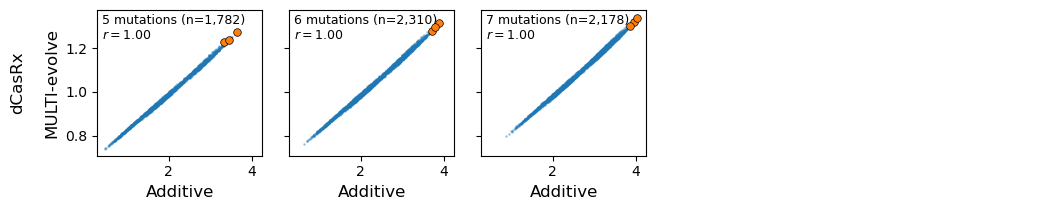

In [13]:
# Tidy combined figure for main.tex — only log2-trained MULTI-evolve.
# Panels for 5, 6, 7 mutations.
import os
from scipy.stats import pearsonr

os.makedirs('../figures', exist_ok=True)

col_add = 'prediction_additive'
col_me = 'multievolve_pred_log2'

ns = [5, 6, 7]
fig, axes = plt.subplots(1, 5, figsize=(10.5, 2.2), sharex="row", sharey="row")

for j, n in enumerate(ns):
    ax = axes[j]
    sub = merged[merged['muts'].apply(len) == n]
    tran_sub = tran_merged[tran_merged['muts'].apply(len) == n]

    ax.scatter(sub[col_add], sub[col_me],
               s=1, alpha=0.3, color='C0', rasterized=True)
    if len(tran_sub) > 0:
        ax.scatter(tran_sub[col_add], tran_sub[col_me],
                   s=30, color='C1', edgecolors='black', linewidths=0.5, zorder=5)

    r, _ = pearsonr(sub[col_add], sub[col_me])
    label = f'{n} mutations (n={len(sub):,})\n$r = {r:.2f}$'
    ax.text(0.03, 0.97, label, transform=ax.transAxes,
            ha='left', va='top', fontsize=9)
    ax.set_xlabel('Additive', fontsize=12)

# Hide unused panels (but keep panel space)
for j in range(3, 5):
    axes[j].set_axis_off()

axes[0].set_ylabel('dCasRx\n\nMULTI-evolve', fontsize=12)

plt.tight_layout()
fig.savefig('../figures/dcasrx_additive_vs_multievolve_tidy.pdf', bbox_inches='tight')
plt.show()


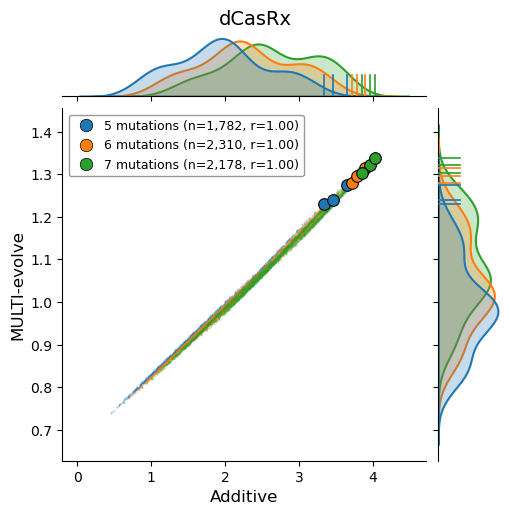

In [14]:
# Seaborn jointplot — single figure, color = mutation number.
# Joint axes: additive vs MULTI-evolve scatter.
# Marginal axes: per-group KDEs, with Tran et al. designs marked as ticks.
import os
import matplotlib as mpl
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

os.makedirs('../figures', exist_ok=True)

col_add = 'prediction_additive'
col_me = 'multievolve_pred_log2'

ns = [5, 6, 7]

sub = merged[merged['muts'].apply(len).isin(ns)].copy()
sub['n_muts'] = sub['muts'].apply(len)

labels_in_order = []
palette = {}
label_map = {}
default_colors = [f'C{i}' for i in range(len(ns))]
for i, n in enumerate(ns):
    grp = sub[sub['n_muts'] == n]
    r, _ = pearsonr(grp[col_add], grp[col_me])
    label = f'{n} mutations (n={len(grp):,}, r={r:.2f})'
    labels_in_order.append(label)
    label_map[n] = label
    palette[label] = default_colors[i]
sub['group'] = sub['n_muts'].map(label_map)
sub['group'] = pd.Categorical(sub['group'], categories=labels_in_order, ordered=True)

g = sns.jointplot(
    data=sub, x=col_add, y=col_me,
    hue='group', palette=palette,
    kind='scatter',
    height=5.2, ratio=5,
    marginal_kws={'common_norm': False, 'fill': True, 'linewidth': 1.5},
    joint_kws={'s': 2, 'alpha': 0.35, 'linewidth': 0, 'rasterized': True},
    hue_order=labels_in_order,
    legend=False,
)

tran_sub = tran_merged[tran_merged['muts'].apply(len).isin(ns)].copy()
tran_sub['n_muts'] = tran_sub['muts'].apply(len)
for n in ns:
    color = palette[label_map[n]]
    tg = tran_sub[tran_sub['n_muts'] == n]
    if len(tg) == 0:
        continue
    g.ax_joint.scatter(
        tg[col_add], tg[col_me],
        s=70, facecolor=color,
        edgecolors='black', linewidths=0.8, zorder=5,
    )
    for xv in tg[col_add]:
        g.ax_marg_x.axvline(xv, color=color, linewidth=1.2,
                            ymin=0.0, ymax=0.35, zorder=6)
    for yv in tg[col_me]:
        g.ax_marg_y.axhline(yv, color=color, linewidth=1.2,
                            xmin=0.0, xmax=0.35, zorder=6)

g.ax_joint.set_xlabel('Additive', fontsize=12)
g.ax_joint.set_ylabel('MULTI-evolve', fontsize=12)
# g.ax_joint.set_ylabel('')
# g.ax_joint.tick_params(labelleft=False)
g.fig.suptitle('dCasRx', fontsize=14)
g.fig.subplots_adjust(top=0.93)

legend_handles = [
    Line2D([0], [0], marker='o', linestyle='',
           markerfacecolor=palette[lbl], markeredgecolor='black',
           markeredgewidth=0.5, markersize=9, label=lbl)
    for lbl in labels_in_order
]
g.ax_joint.legend(handles=legend_handles, loc='upper left', fontsize=9,
                  frameon=True, fancybox=True, edgecolor='gray',
                  handletextpad=0.4, borderpad=0.4, title=None)

g.fig.savefig('../figures/dcasrx_additive_vs_multievolve_jointplot.pdf',
              bbox_inches='tight')
plt.show()


In [15]:
## Load 0-layer MULTI-evolve predictions and compute naive additive baseline
# The naive additive model takes single-mutant measurements (log2 FI) directly as
# per-mutation effects, with no regression: y_hat = sum over muts of effect[m].

# 0-layer MULTI-evolve proposals (log2-trained)
me0 = pd.read_csv('../output/dcasrx/dcasrx_0layer_multievolve_proposals.csv')
me0['muts_s'] = me0['Mut_string'].apply(lambda x: str(sorted(x.split('/'))))
me0 = me0[me0['num_muts'].between(5, 7)]
merged = merged.merge(
    me0[['muts_s', 'average']].rename(columns={'average': 'prediction_0layer'}),
    on='muts_s', how='left',
)
print(f'0-layer joined: {merged["prediction_0layer"].notna().sum()} rows')

# Naive additive prediction: sum of single-mutant log2 fold-change effects
single_effect = effect_dictionary['single_effect']
merged['prediction_additive_naive'] = merged['muts'].apply(
    lambda ms: sum(single_effect[m] for m in ms)
)
tran_merged = merged[merged['muts_s'].isin(targets)]
print(f'Paper variants after re-merge: {len(tran_merged)} / {len(targets)}')


0-layer joined: 6270 rows
Paper variants after re-merge: 9 / 9


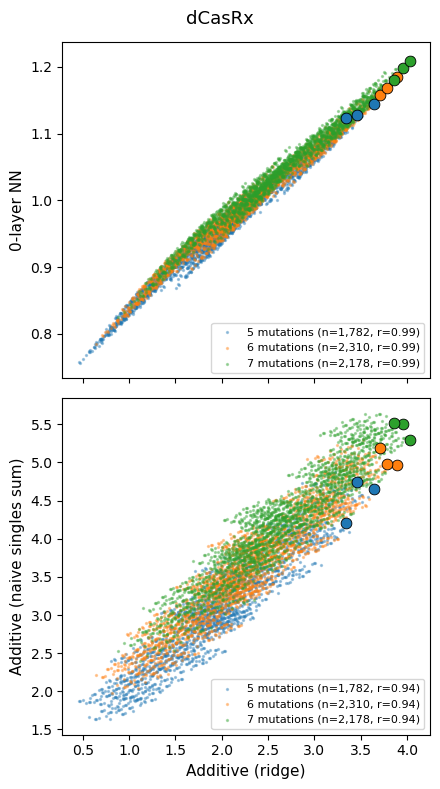

In [16]:
## Two-panel figure: 0-layer vs additive (ridge), and naive additive vs additive (ridge)
from scipy.stats import pearsonr
import os

os.makedirs('../figures', exist_ok=True)

col_ridge = 'prediction_additive'
col_0lay  = 'prediction_0layer'
col_naive = 'prediction_additive_naive'

sub       = merged[merged[col_0lay].notna()].copy()
sub['n_muts'] = sub['muts'].apply(len)
tran_sub  = tran_merged[tran_merged[col_0lay].notna()].copy()
tran_sub['n_muts'] = tran_sub['muts'].apply(len)

ns = [5, 6, 7]
colors = [f'C{i}' for i in range(len(ns))]

fig, axes = plt.subplots(2, 1, figsize=(4.5, 8), sharex=True)

panels = [
    (axes[0], col_ridge, col_0lay,  '', '0-layer NN'),
    (axes[1], col_ridge, col_naive, 'Additive (ridge)', 'Additive (naive singles sum)'),
]

for ax, xcol, ycol, xlab, ylab in panels:
    for i, n in enumerate(ns):
        grp   = sub[sub['n_muts'] == n]
        tgrp  = tran_sub[tran_sub['n_muts'] == n]
        if len(grp) == 0:
            continue
        r, _ = pearsonr(grp[xcol], grp[ycol])
        ax.scatter(grp[xcol], grp[ycol], s=2, alpha=0.35, color=colors[i],
                   rasterized=True,
                   label=f'{n} mutations (n={len(grp):,}, r={r:.2f})')
        if len(tgrp):
            ax.scatter(tgrp[xcol], tgrp[ycol], s=60, color=colors[i],
                       edgecolors='black', linewidths=0.6, zorder=5)
    ax.set_xlabel(xlab, fontsize=11)
    ax.set_ylabel(ylab, fontsize=11)
    ax.legend(fontsize=8, loc='lower right', frameon=True)

fig.suptitle('dCasRx', fontsize=13)
plt.tight_layout()
fig.savefig('../figures/dcasrx_ridge_vs_0layer_and_naive.pdf', bbox_inches='tight')
plt.show()
